In [ ]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn nltk

In [ ]:
import re
import html
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

warnings.filterwarnings("ignore")

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
dataset = load_dataset("stanfordnlp/imdb")

df = pd.DataFrame(dataset["train"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five reviews:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (25000, 2)

Column names:
['text', 'label']

First five reviews:


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [1]:
%pip install -q datasets

from datasets import load_dataset
import pandas as pd

# Load the IMDb sentiment dataset
dataset = load_dataset("stanfordnlp/imdb")

# Convert training data into a Pandas DataFrame
df = pd.DataFrame(dataset["train"])

# Rename columns to match our project code
df = df.rename(columns={
    "text": "review",
    "label": "sentiment"
})

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset loaded successfully!
Dataset shape: (25000, 2)
Column names: ['review', 'sentiment']


,review,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [3]:
# Rename columns
df = df.rename(columns={
    "text": "review",
    "label": "sentiment"
})

# Keep only the required columns
df = df[["review", "sentiment"]].copy()

# Remove missing values
df = df.dropna(subset=["review", "sentiment"])

# Convert reviews to strings
df["review"] = df["review"].astype(str)

print("Dataset prepared successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nFirst 5 reviews:")
display(df.head())

Dataset prepared successfully!
Dataset shape: (25000, 2)

Column names:
['review', 'sentiment']

Sentiment distribution:
sentiment
0    12500
1    12500
Name: count, dtype: int64

First 5 reviews:


,review,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [4]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Prepare stopwords and lemmatizer
stop_words = set(stopwords.words("english"))

# Preserve negation words
stop_words -= {"no", "nor", "not"}

lemmatizer = WordNetLemmatizer()


def preprocess_text(text):
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Extract words
    words = re.findall(r"\b[a-z]+\b", text)

    # Remove stopwords and lemmatize
    cleaned_words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return " ".join(cleaned_words)


# Apply preprocessing
df["cleaned_review"] = df["review"].apply(preprocess_text)

print("Text preprocessing completed!")

display(df[["review", "cleaned_review", "sentiment"]].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Text preprocessing completed!


,review,cleaned_review,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,rented curious yellow video store controversy ...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",curious yellow risible pretentious steaming pi...,0
2,If only to avoid making this type of film in t...,avoid making type film future film interesting...,0
3,This film was probably inspired by Godard's Ma...,film probably inspired godard masculin urge se...,0
4,"Oh, brother...after hearing about this ridicul...",oh brother hearing ridiculous film umpteen yea...,0


In [5]:
from sklearn.model_selection import train_test_split

# Input features and target labels
X = df["cleaned_review"]
y = df["sentiment"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split completed!")

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Dataset split completed!
Training reviews: 20000
Testing reviews: 5000

Training sentiment distribution:
sentiment
1    10000
0    10000
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
1    2500
0    2500
Name: count, dtype: int64


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Learn vocabulary from training data and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("Training feature matrix:", X_train_tfidf.shape)
print("Testing feature matrix:", X_test_tfidf.shape)

print("\nNumber of TF-IDF features:", len(tfidf.get_feature_names_out()))

TF-IDF conversion completed!
Training feature matrix: (20000, 5000)
Testing feature matrix: (5000, 5000)

Number of TF-IDF features: 5000


In [7]:
from sklearn.naive_bayes import MultinomialNB

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_tfidf, y_train)

# Predict sentiment for test reviews
nb_predictions = nb_model.predict(X_test_tfidf)

print("Multinomial Naive Bayes training completed!")
print("Total predictions:", len(nb_predictions))

Multinomial Naive Bayes training completed!
Total predictions: 5000


In [8]:
from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train_tfidf, y_train)

# Predict sentiment for test reviews
lr_predictions = lr_model.predict(X_test_tfidf)

print("Logistic Regression training completed!")
print("Total predictions:", len(lr_predictions))

Logistic Regression training completed!
Total predictions: 5000


In [9]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Store model predictions
models = {
    "Multinomial Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions
}

results = []

# Calculate performance metrics
for model_name, predictions in models.items():

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

# Display results
results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
display(results_df.round(4))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.8492,0.8486,0.850,0.8493
1,Logistic Regression,0.8896,0.8787,0.904,0.8912


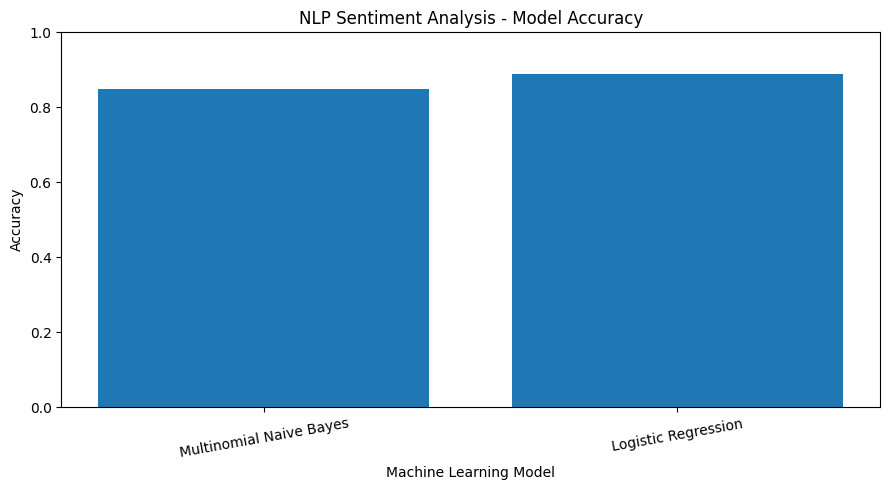

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.title("NLP Sentiment Analysis - Model Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import classification_report

print("=" * 50)
print("MULTINOMIAL NAIVE BAYES")
print("=" * 50)

print(
    classification_report(
        y_test,
        nb_predictions,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

print("=" * 50)
print("LOGISTIC REGRESSION")
print("=" * 50)

print(
    classification_report(
        y_test,
        lr_predictions,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

    Negative       0.85      0.85      0.85      2500
    Positive       0.85      0.85      0.85      2500

    accuracy                           0.85      5000
   macro avg       0.85      0.85      0.85      5000
weighted avg       0.85      0.85      0.85      5000

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    Negative       0.90      0.88      0.89      2500
    Positive       0.88      0.90      0.89      2500

    accuracy                           0.89      5000
   macro avg       0.89      0.89      0.89      5000
weighted avg       0.89      0.89      0.89      5000



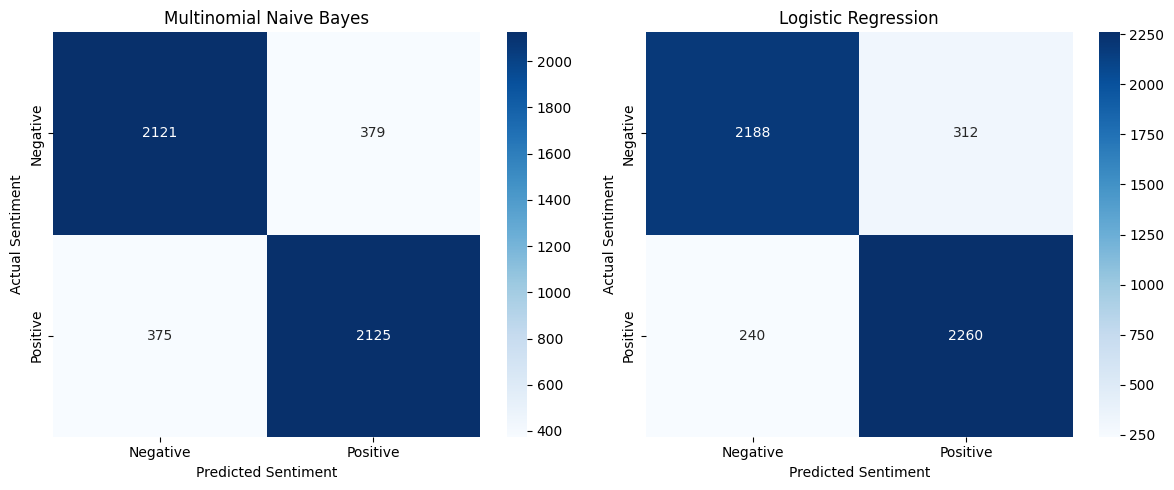

In [12]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

model_data = [
    ("Multinomial Naive Bayes", nb_predictions),
    ("Logistic Regression", lr_predictions)
]

for ax, (model_name, predictions) in zip(axes, model_data):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Sentiment")
    ax.set_ylabel("Actual Sentiment")

plt.tight_layout()
plt.show()

In [14]:
def predict_sentiment(text):

    # Preprocess the input review
    cleaned_text = preprocess_text(text)

    # Convert text into TF-IDF features
    text_vector = tfidf.transform([cleaned_text])

    # Predict sentiment using Logistic Regression
    prediction = lr_model.predict(text_vector)[0]

    # Calculate prediction confidence
    probabilities = lr_model.predict_proba(text_vector)[0]
    confidence = probabilities[int(prediction)] * 100

    # Convert prediction to text
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("\nReview:", text)
    print("Predicted Sentiment:", sentiment)
    print(f"Prediction Confidence: {confidence:.2f}%")

    return sentiment


print("predict_sentiment() function defined successfully!")

predict_sentiment() function defined successfully!


In [15]:
predict_sentiment(
    "This movie was fantastic, amazing and entertaining!"
)


Review: This movie was fantastic, amazing and entertaining!
Predicted Sentiment: Positive
Prediction Confidence: 99.37%


'Positive'

In [16]:
predict_sentiment(
    "This movie was boring, disappointing and a waste of time."
)


Review: This movie was boring, disappointing and a waste of time.
Predicted Sentiment: Negative
Prediction Confidence: 99.93%


'Negative'

In [17]:
best_model = results_df.loc[
    results_df["Accuracy"].idxmax()
]

print("=" * 50)
print("FINAL PROJECT RESULTS")
print("=" * 50)

display(results_df.round(4))

print("\nBest model:", best_model["Model"])
print(f"Best accuracy: {best_model['Accuracy']:.4f}")

print("\nProject completed successfully!")

FINAL PROJECT RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
0,Multinomial Naive Bayes,0.8492,0.8486,0.850,0.8493
1,Logistic Regression,0.8896,0.8787,0.904,0.8912



Best model: Logistic Regression
Best accuracy: 0.8896

Project completed successfully!
